In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pickle

In [11]:
PATH = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qNLP_Efficiency/qnlp_in_practice/"

In [15]:
random_directory_path = "code/rp_runs/noise_random/"
pretrained_directory_path = "code/rp_runs/noise_pretrained/"

def get_training_path(directory_path, niter=100):
    directory_path = PATH+ directory_path
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))

    iters_selected = np.zeros(shape=(len(files), 11))
    error_test_histories = np.zeros(shape=(len(files), 11))

    for f_index, file in enumerate(files):
        with open(file, 'rb') as file:
            data = pickle.load(file)
        if len(data['error_history']) != 100:
            print(file.name + " Has less than 100 iterations!")
            break

        cost_histories[f_index, :] = data['func_history']
        error_train_histories[f_index, :] = data['error_history'] 
        error_test_histories[f_index, :] = data['test_error_list']
        iters_selected[f_index, :] = data['iters_selected']

        assert(len(data['test_error_list']) == len(data['iters_selected']))
        assert(len(data['func_history']) == len(data['error_history']))

    cost_history_mean = cost_histories.mean(0)
    error_train_history_mean = error_train_histories.mean(0)

    error_test_history_mean = error_test_histories.mean(0)
    return cost_history_mean, error_train_history_mean, error_test_history_mean

random_cost, random_train, random_test = get_training_path(random_directory_path)
pretrained_cost, pretrained_train, pretrained_test = get_training_path(pretrained_directory_path)

C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qNLP_Efficiency/qnlp_in_practice/code/rp_runs/noise_pretrained/RP_noise_pretrained_44_0.pickle Has less than 100 iterations!


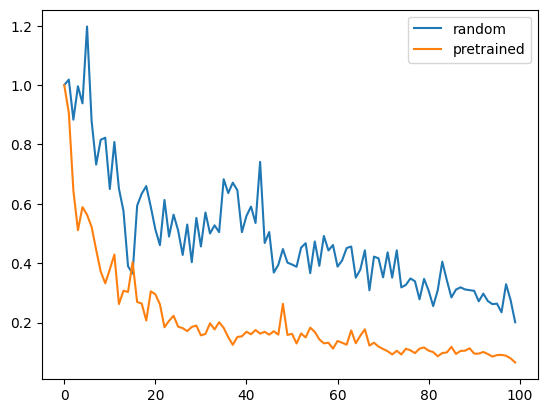

In [16]:
plt.plot(random_cost/random_cost[0], label='random')
plt.plot(pretrained_cost/pretrained_cost[0], label='pretrained')
plt.legend()

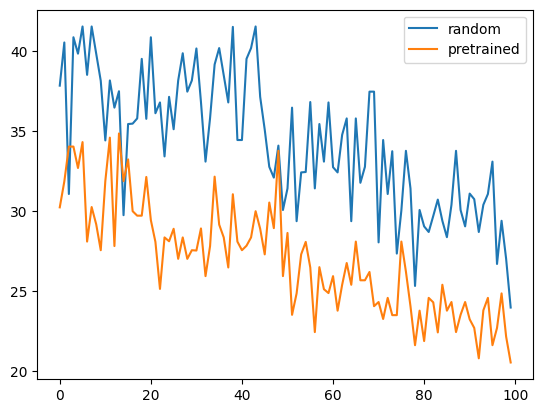

In [17]:
plt.plot(random_train, label='random')
plt.plot(pretrained_train, label='pretrained')
plt.legend()

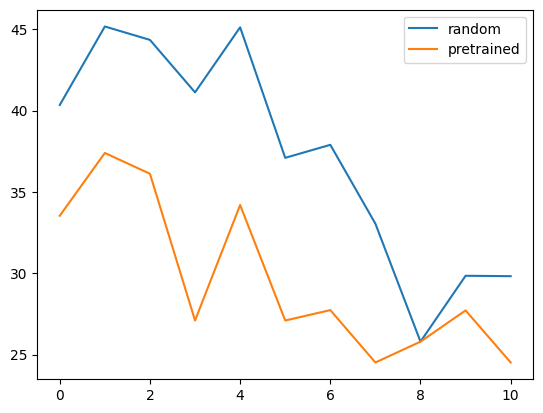

In [18]:
plt.plot(random_test, label='random')
plt.plot(pretrained_test, label='pretrained')
plt.legend()

In [19]:
random_directory_path = "code/mc_runs/noise_random/"
pretrained_directory_path = "code/mc_runs/noise_pretrained/"

def get_training_path(directory_path, niter=100):
    directory_path = PATH+ directory_path
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))

    iters_selected = np.zeros(shape=(len(files), 11))
    error_test_histories = np.zeros(shape=(len(files), 11))

    for f_index, file in enumerate(files):
        with open(file, 'rb') as file:
            data = pickle.load(file)
        if len(data['error_history']) == 100:
            print(1, file)
            cost_histories[f_index, :] = data['func_history']
            error_train_histories[f_index, :] = data['error_history']
            error_test_histories[f_index, :] = data['test_error_list']
            iters_selected[f_index, :] = data['iters_selected']

            assert(len(data['test_error_list']) == len(data['iters_selected']))
            assert(len(data['func_history']) == len(data['error_history']))
        else:
            print(file)
        plt.plot(error_train_histories[f_index, :])

    cost_history_mean = cost_histories.mean(0)
    error_train_history_mean = error_train_histories.mean(0)

    error_test_history_mean = error_test_histories.mean(0)
    return cost_history_mean, error_train_history_mean, error_test_history_mean, iters_selected

#random_cost, random_train, random_test, random_iters_selected = get_training_path(random_directory_path)
pretrained_cost, pretrained_train, pretrained_test, pretrained_iters_selected = get_training_path(pretrained_directory_path)

C:\Users\henry\AppData\Local\Temp\ipykernel_23516\3994868836.py:30: RuntimeWarning: Mean of empty slice.
  cost_history_mean = cost_histories.mean(0)
c:\Users\henry\Desktop\UCL\ExtraQNLPWork\env_qnlp\lib\site-packages\numpy\core\_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
C:\Users\henry\AppData\Local\Temp\ipykernel_23516\3994868836.py:31: RuntimeWarning: Mean of empty slice.
  error_train_history_mean = error_train_histories.mean(0)
C:\Users\henry\AppData\Local\Temp\ipykernel_23516\3994868836.py:33: RuntimeWarning: Mean of empty slice.
  error_test_history_mean = error_test_histories.mean(0)
c:\Users\henry\Desktop\UCL\ExtraQNLPWork\env_qnlp\lib\site-packages\numpy\core\_methods.py:121: RuntimeWarning: divide by zero encountered in divide
  ret = um.true_divide(


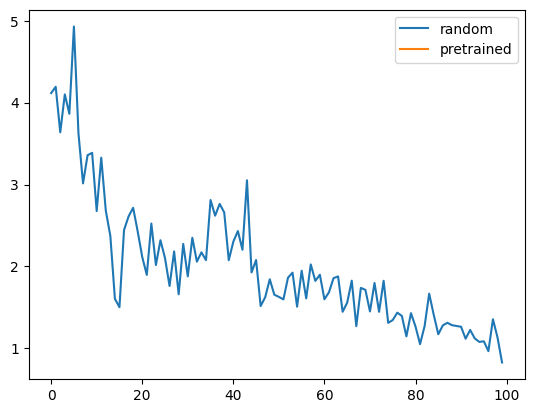

In [20]:
plt.plot(random_cost, label='random')
plt.plot(pretrained_cost, label='pretrained')
plt.legend()

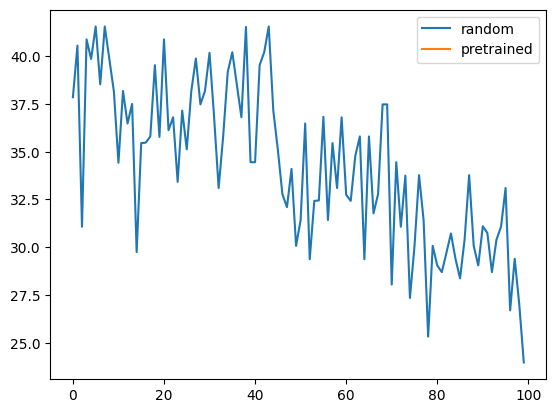

In [21]:
plt.plot(random_train, label='random')
plt.plot(pretrained_train, label='pretrained')
plt.legend()

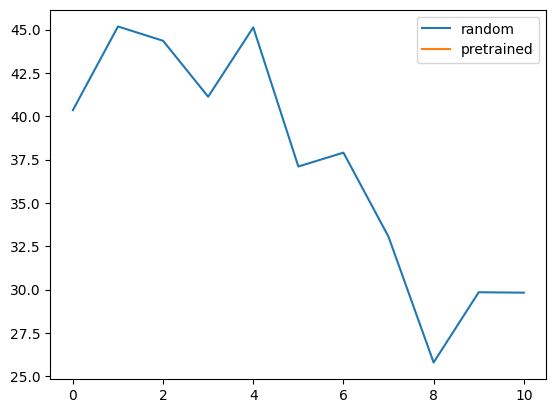

In [22]:
plt.plot(random_test, label='random')
plt.plot(pretrained_test, label='pretrained')
plt.legend()

NameError: name 'random_iters_selected' is not defined

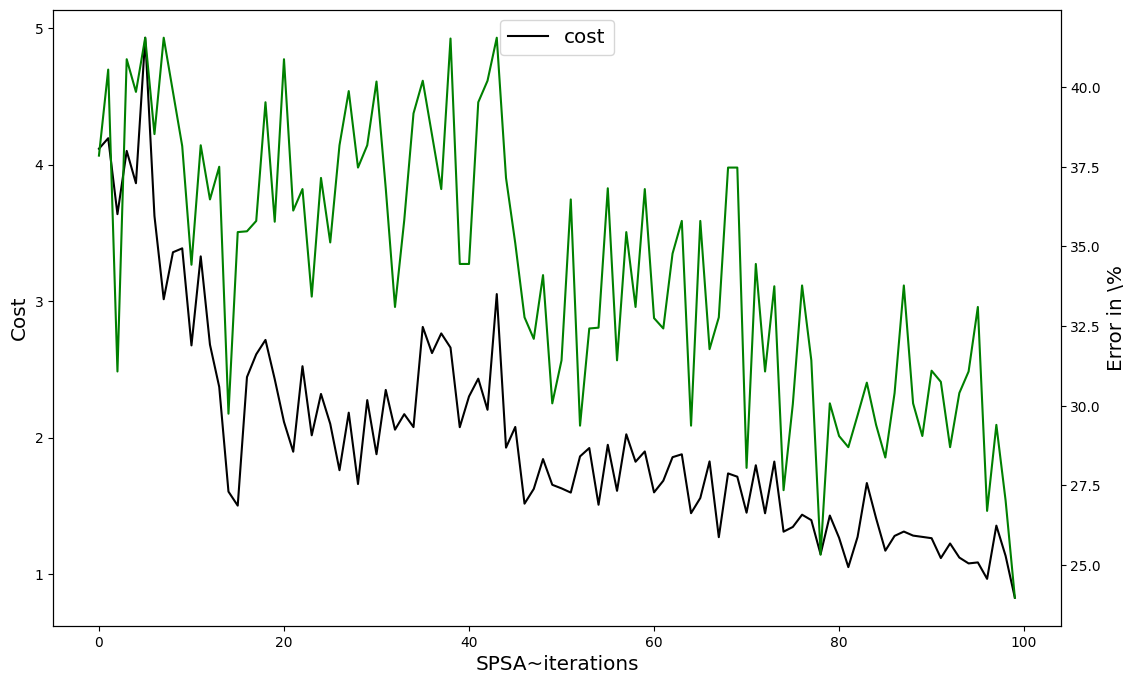

In [23]:
#****************************************************
# Summary plot
#****************************************************
from matplotlib import pyplot as plt

fig, ax1 = plt.subplots(figsize=(13, 8))

ax1.plot(range(len(random_cost)), random_cost, '-k', markersize=4, label='cost')
ax1.set_ylabel(r"Cost", fontsize='x-large')
ax1.set_xlabel(r"SPSA~iterations", fontsize='x-large')
ax1.legend(loc='upper center', fontsize='x-large')

ax2 = ax1.twinx()
ax2.set_ylabel(r"Error in \%", fontsize='x-large')
ax2.plot(range(len(random_train)), random_train, '-g', markersize=4, label='training error')
ax2.plot(random_iters_selected[0], random_test, 'xb', markersize=7, label='testing error')
ax2.legend(loc='upper right', fontsize='x-large')

plt.title('RP task, quantum run -- results', fontsize='x-large')
plt.savefig('RP_task_Results_noise_pretrained.png', dpi=300, facecolor='white')  
plt.show()

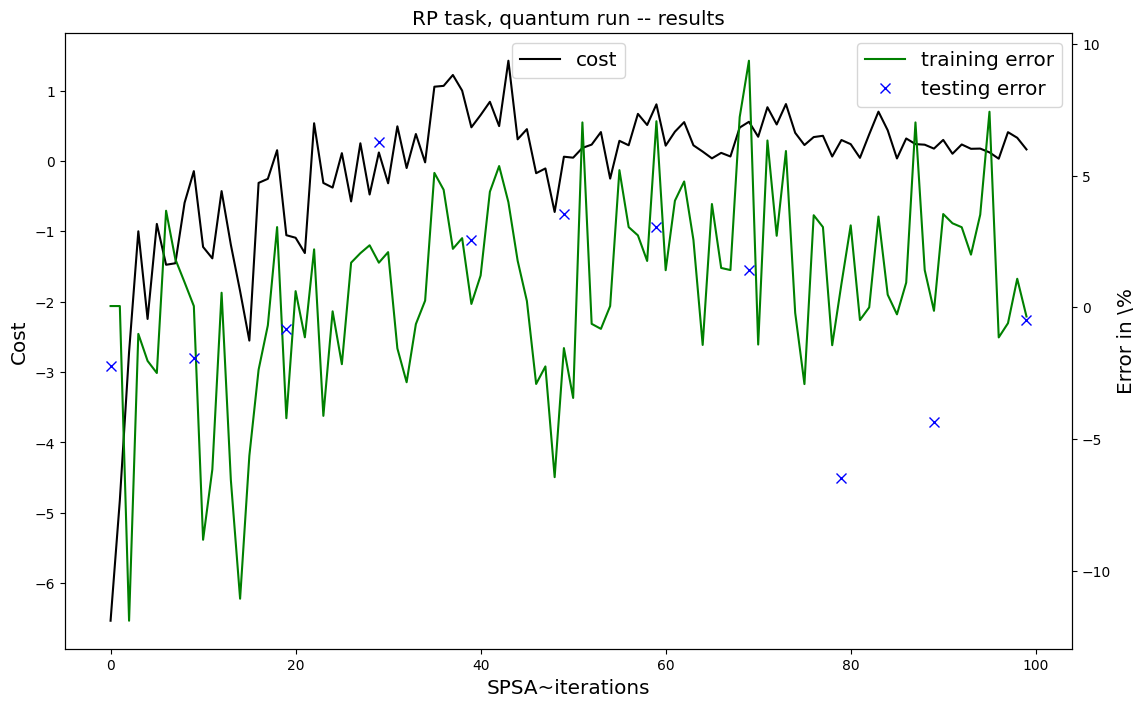

In [54]:
#****************************************************
# Summary plot
#****************************************************
from matplotlib import pyplot as plt

fig, ax1 = plt.subplots(figsize=(13, 8))

ax1.plot(range(len(pretrained_cost)), random_cost-pretrained_cost, '-k', markersize=4, label='cost')
ax1.set_ylabel(r"Cost", fontsize='x-large')
ax1.set_xlabel(r"SPSA~iterations", fontsize='x-large')
ax1.legend(loc='upper center', fontsize='x-large')

ax2 = ax1.twinx()
ax2.set_ylabel(r"Error in \%", fontsize='x-large')
ax2.plot(range(len(pretrained_train)), random_train-pretrained_train, '-g', markersize=4, label='training error')
ax2.plot(pretrained_iters_selected[0], random_test-pretrained_test, 'xb', markersize=7, label='testing error')
ax2.legend(loc='upper right', fontsize='x-large')

plt.title('RP task, quantum run -- results', fontsize='x-large')
plt.savefig('RP_task_Results_noise_pretrained.png', dpi=300, facecolor='white')
plt.show()